In [27]:
# import necessary packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris
from matplotlib.patches import Patch

In [12]:
# establish paths to datasets - fire
project_fldr = Path.cwd().parents[1]
raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in the processed fire dataset
fire_path = processed_fldr / "fire_shp_25" / "fire_shp_25.shp"
fire = gpd.read_file(fire_path)

print("fire shape:", fire.shape)
print(fire.crs)




fire shape: (521, 23)
EPSG:3310


In [13]:
# establish paths to datasets - wetlands

# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
wetlands_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands_subset' / 'wetlands_subset.geojson'
print(wetlands_path.exists())

Box folder found at /Users/masonbunker/Library/CloudStorage/Box-Box
True


In [14]:
# read in the wetlands geojson file, this will take a WHILE - 10 mins 1st try 
wetlands = gpd.read_file(wetlands_path, engine="pyogrio")


Using the default year of 2024
EPSG:4269


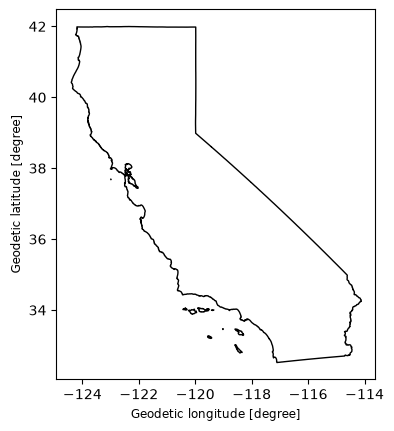

In [15]:
# make map just for CA
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']

ca_outline.plot(color= "#ffffff", edgecolor = "#000000")

print(ca_outline.crs)



In [16]:
# put all three shapes into same cord ref system

#using wetlands as the default since it is the largest
wetlands = wetlands.to_crs("EPSG:26910")
ca_outline = ca_outline.to_crs("EPSG:26910")
fire = fire.to_crs("EPSG:26910")


Text(0.5, 1.0, 'California Wetlands and 2025 Wildfires')

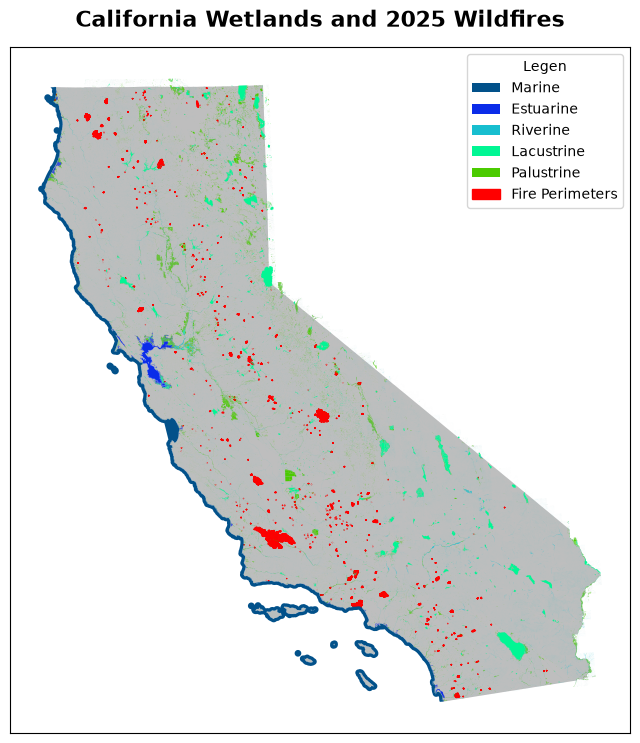

In [ ]:
# create one map for all three datasets to combine
# this establishes the initial figure that the other figures will be added to (using ax to specify the same axes)
fig, ax = plt.subplots(figsize=(8, 10))

#plot california outline
ca_outline.plot(ax = ax, color= "#bebebe"), #edgecolor = "#000000")


#plot fires
fire.plot(ax=ax,figsize=(10,10), color='red', edgecolor='red')

#plot wetlands, by system color
system_colors = {
    "Marine": "#02518a",
    "Estuarine": "#0b2ce9",
    "Riverine": "#17becf",
    "Lacustrine": "#01f694",
    "Palustrine": "#4bcb00"
}
wetlands.plot(
    color= wetlands["C System"].map(system_colors), 
    #edgecolor=wetlands["C System"].map(system_colors), #this makes everything riverine in the background
    ax=ax, 
)

#create custom legend because when you use color geopandas doesn't do it automatically
legend_elements = [
    Patch(facecolor=color, label=system)
    for system, color in system_colors.items()
]

legend_elements.append(
    Patch(facecolor="red", edgecolor="red", label="Fire Perimeters")
)

ax.legend(
    handles=legend_elements,
    title="Legend",
    loc="upper right"
)

# turn off the axes
ax.axis=('off')
ax.get_xaxis().set_visible(False) # Explicitly hide X elements
ax.get_yaxis().set_visible(False)

ax.set_title(
    "California Wetlands > 1HA and 2025 Wildfires",
    fontsize=16,
    fontweight="bold",
    pad=15
)

In [ ]:
# use fire.explore()#to see what things look like

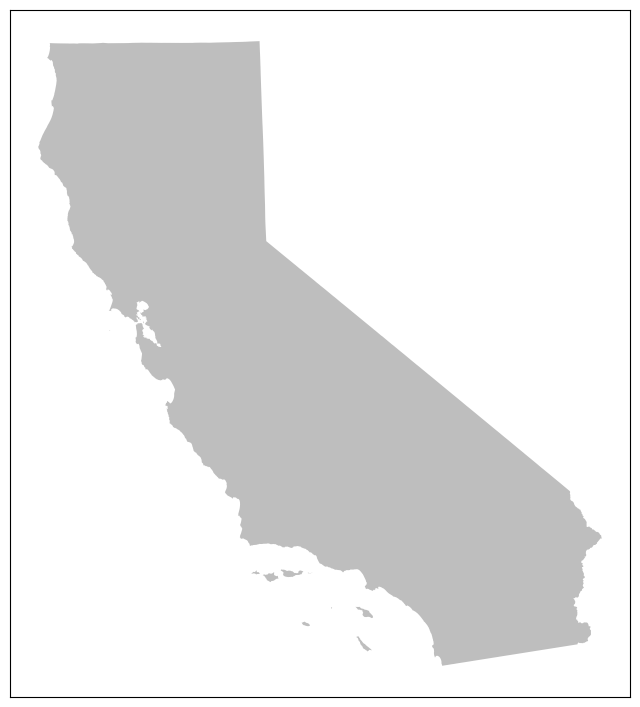

In [35]:
# make 6 subplots and combine them to have them to show each variable independently
fig2, ax2 = plt.subplots(figsize=(8, 10))
ca_outline.plot(ax = ax2, color= "#bebebe"), #edgecolor = "#000000")

ax2.axis=('off')
ax2.get_xaxis().set_visible(False) # Explicitly hide X elements
ax2.get_yaxis().set_visible(False)
